# Clase 7 · Laboratorio — Modelos No Supervisados sobre Saber 11

**Trabajo en parejas · 90 min.**

En la pre-clase viste todos los modelos funcionando. En este laboratorio analizarás los datos desde ángulos más complejos: ¿cuántos perfiles de colegios existen en Colombia? ¿Qué departamentos son anomalías? ¿Se puede predecir el cluster de un nuevo estudiante?

**Checkpoint del profesor a los 50 min** (después de la Tarea 3).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings; warnings.filterwarnings('ignore')

df = pd.read_csv("datos/saber11_muestra_500k.csv")
df["ESTRATO_NUM"] = df["FAMI_ESTRATOVIVIENDA"].astype("string").str.extract(r"(\d+)").astype(float)
PUNTAJES = ["PUNT_LECTURA_CRITICA","PUNT_MATEMATICAS","PUNT_C_NATURALES",
            "PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES"]

print(f"Dataset: {len(df):,} filas × {df.shape[1]} columnas")

Dataset: 500,000 filas × 52 columnas


## Tarea 1 (20 min) — Perfiles de colegios en Colombia

En lugar de segmentar estudiantes (como en la pre-clase), segmenta **colegios** usando su puntaje promedio.

1. Agrupa el dataset por `COLE_NOMBRE_ESTABLECIMIENTO` y calcula el promedio de los 5 puntajes y el estrato promedio. Filtra colegios con al menos 30 estudiantes.
2. Escala las variables.
3. Aplica K-Means y usa el método del codo + Silhouette para elegir K (entre 2 y 8).
4. Para cada cluster: ¿qué tipo de colegio describe? Muestra el promedio de las variables y la distribución de `COLE_NATURALEZA` y `COLE_AREA_UBICACION` dentro de cada cluster.
5. ¿Cuáles son los 5 colegios "más típicos" del cluster de mayor puntaje? ¿Los reconoces?

Colegios con ≥30 estudiantes: 5,034


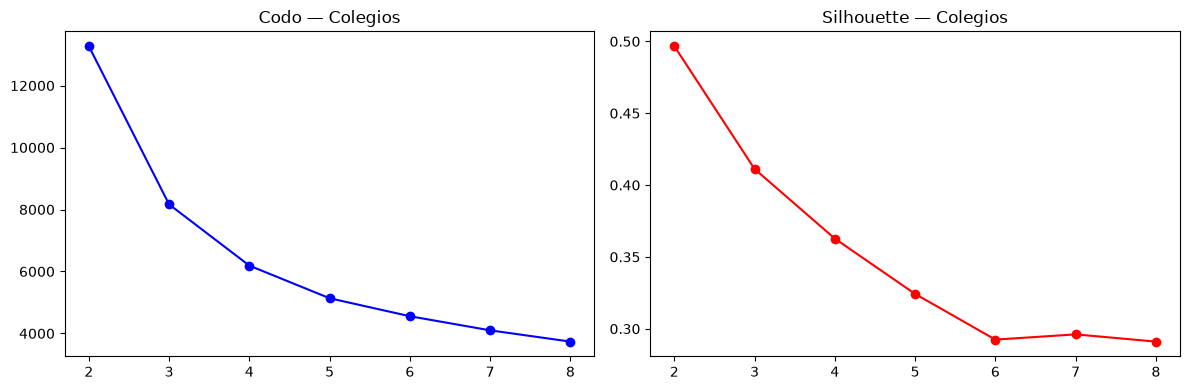

K sugerido: 2

=== Perfil por cluster ===
         PUNT_LECTURA_CRITICA  PUNT_MATEMATICAS  PUNT_C_NATURALES  \
cluster                                                             
0                        49.3              47.0              45.5   
1                        59.7              59.0              56.1   

         PUNT_SOCIALES_CIUDADANAS  PUNT_INGLES  ESTRATO_NUM  
cluster                                                      
0                            43.4         44.7          1.9  
1                            55.2         59.6          2.6  

=== Naturaleza por cluster ===
COLE_NATURALEZA  NO OFICIAL  OFICIAL
cluster                             
0                       471     3024
1                       789      750

=== Top 5 colegios del cluster élite (cluster 1) ===
COLE_NOMBRE_ESTABLECIMIENTO
COLEGIO ANGLO AMERICANO                                76.101266
COL NUEVO COLOMBO AMERICANO                            76.038298
COL BILINGUE DIVINO NIÑO                 

In [2]:
# 1: agregar por colegio (≥30 estudiantes)
colegios_extra = df.groupby("COLE_NOMBRE_ESTABLECIMIENTO").agg(
    n_estudiantes=("PUNT_MATEMATICAS","count"),
    COLE_NATURALEZA=("COLE_NATURALEZA","first"),
    COLE_AREA_UBICACION=("COLE_AREA_UBICACION","first"),
    COLE_JORNADA=("COLE_JORNADA","first") if "COLE_JORNADA" in df.columns else ("PUNT_MATEMATICAS","count"),
    **{p: (p,"mean") for p in PUNTAJES},
    ESTRATO_NUM=("ESTRATO_NUM","mean")
).query("n_estudiantes >= 30").dropna()

print(f"Colegios con ≥30 estudiantes: {len(colegios_extra):,}")
colegios = colegios_extra.copy()

# 2: escalar
X_colegios = StandardScaler().fit_transform(colegios[PUNTAJES + ["ESTRATO_NUM"]])

# 3: Elbow + Silhouette
inercias_c, silhouettes_c = [], []
for k in range(2, 9):
    km_c = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels_c = km_c.fit_predict(X_colegios)
    inercias_c.append(km_c.inertia_)
    silhouettes_c.append(silhouette_score(X_colegios, labels_c))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(2, 9), inercias_c, "b-o"); axes[0].set_title("Codo — Colegios")
axes[1].plot(range(2, 9), silhouettes_c, "r-o"); axes[1].set_title("Silhouette — Colegios")
plt.tight_layout(); plt.show()

# 4: K-Means final + perfil
K_col = range(2, 9)[np.argmax(silhouettes_c)]  # tu K elegido
print(f"K sugerido: {K_col}")
km_col = KMeans(n_clusters=K_col, n_init=10, random_state=42)
colegios["cluster"] = km_col.fit_predict(X_colegios)

print("\n=== Perfil por cluster ===")
print(colegios.groupby("cluster")[PUNTAJES + ["ESTRATO_NUM"]].mean().round(1))
print("\n=== Naturaleza por cluster ===")
print(colegios.groupby(["cluster","COLE_NATURALEZA"]).size().unstack(fill_value=0))

# 5: top 5 colegios del cluster élite
cluster_elite = colegios.groupby("cluster")[PUNTAJES].mean().sum(axis=1).idxmax()
top5 = colegios[colegios["cluster"]==cluster_elite][PUNTAJES].mean(axis=1).nlargest(5)
print(f"\n=== Top 5 colegios del cluster élite (cluster {cluster_elite}) ===")
print(top5)
print(colegios.groupby(["cluster", "COLE_AREA_UBICACION"])
      .size().unstack(fill_value=0))

In [3]:
# 5 (complemento): "más típicos" = colegios más cercanos al centroide del cluster élite
# (el top 5 de arriba muestra los de mayor puntaje, que son los extremos del cluster, no los típicos)
mask_elite = (colegios["cluster"] == cluster_elite).to_numpy()
dist_centroide = np.linalg.norm(X_colegios[mask_elite] - km_col.cluster_centers_[cluster_elite], axis=1)
tipicos = (colegios[mask_elite]
           .assign(dist_centroide=dist_centroide)
           .nsmallest(5, "dist_centroide")
           [["COLE_NATURALEZA", "COLE_AREA_UBICACION", "n_estudiantes", "dist_centroide"] + PUNTAJES + ["ESTRATO_NUM"]])
print(f"=== 5 colegios más típicos del cluster élite (cluster {cluster_elite}) ===")
print(tipicos.round(2).to_string())

=== 5 colegios más típicos del cluster élite (cluster 1) ===
                                       COLE_NATURALEZA COLE_AREA_UBICACION  n_estudiantes  dist_centroide  PUNT_LECTURA_CRITICA  PUNT_MATEMATICAS  PUNT_C_NATURALES  PUNT_SOCIALES_CIUDADANAS  PUNT_INGLES  ESTRATO_NUM
COLE_NOMBRE_ESTABLECIMIENTO                                                                                                                                                                                            
GIMNASIO SAN MATEO                          NO OFICIAL              URBANO             72            0.21                 60.47             59.83             56.01                     55.44        59.88         2.57
COLEGIO COMFAMILIAR DEL ATLANTICO           NO OFICIAL              URBANO             53            0.21                 60.85             59.15             56.25                     55.36        60.08         2.58
CENT EDUC DE NSTRA SRA DE LA PAZ            NO OFICIAL              URBANO 

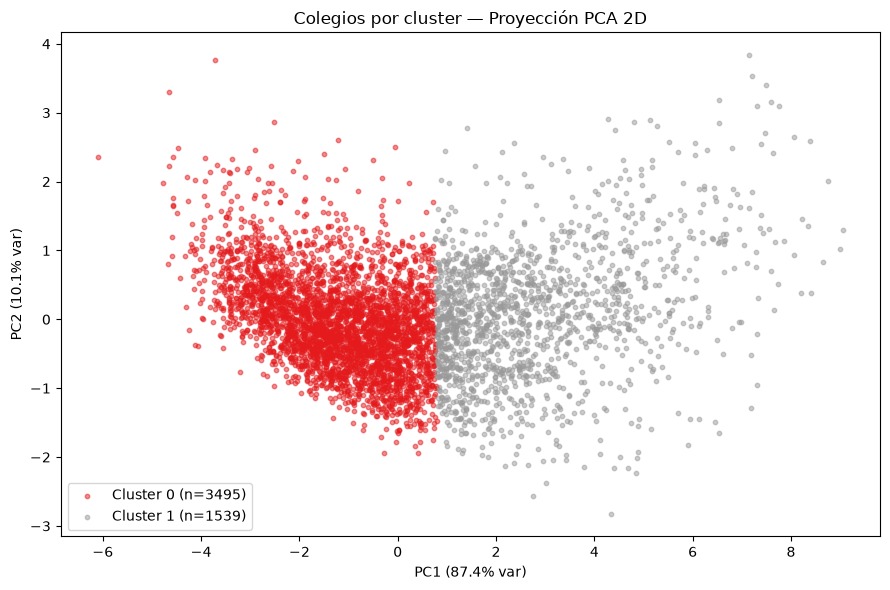

In [4]:
# Visualización PCA de clusters de colegios
pca_col = PCA(n_components=2)
coords_col = pca_col.fit_transform(X_colegios)
colores_col = plt.cm.Set1(np.linspace(0,1,K_col))

fig, ax = plt.subplots(figsize=(9,6))
for k in range(K_col):
    mask = colegios["cluster"] == k
    ax.scatter(coords_col[mask,0], coords_col[mask,1], alpha=0.5, s=10,
               color=colores_col[k], label=f"Cluster {k} (n={mask.sum()})")
ax.set_xlabel(f"PC1 ({pca_col.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({pca_col.explained_variance_ratio_[1]*100:.1f}% var)")
ax.set_title("Colegios por cluster — Proyección PCA 2D")
ax.legend(); plt.tight_layout(); plt.show()

**Pregunta analítica:** ¿Los clusters de colegios coinciden con lo que esperarías según la naturaleza del colegio (oficial vs privado) o su ubicación (urbano vs rural)?

**Respuesta.** Coinciden, pero solo en parte. K-Means con K=2 (máximo Silhouette, 0,497) separa un cluster de **desempeño bajo-medio** (cluster 0: 3.495 colegios, promedios entre 43 y 49, estrato 1,9) de uno de **desempeño alto** (cluster 1: 1.539 colegios, promedios entre 55 y 60, estrato 2,6).

- **Ubicación — se alinea bastante.** El 91 % de los colegios rurales (789 de 867) cae en el cluster bajo, y el cluster alto es 95 % urbano.
- **Naturaleza — se alinea menos de lo esperado.** El cluster bajo sí es 87 % oficial, pero el cluster alto está repartido casi mitad y mitad (789 privados y 750 oficiales), y 471 colegios privados (37 % de los privados) quedan en el cluster bajo. Ser privado no garantiza estar arriba, ni ser oficial condena a estar abajo.
- **Estrato** acompaña la separación (1,9 vs 2,6): la brecha que captura el modelo es sobre todo **urbano-rural y socioeconómica**.

El gráfico PCA muestra que no hay dos nubes separadas: PC1 explica el 87,4 % de la varianza (es básicamente el "nivel general de puntaje", porque los 5 puntajes están correlacionados por encima de 0,9) y K=2 corta ese continuo en PC1 ≈ 0,8. Los clusters son **niveles de desempeño**, no tipos de colegio cualitativamente distintos.

**Punto 5 — ¿Los reconoces?** El top 5 por puntaje son colegios privados bilingües conocidos por liderar los rankings de Saber 11: Anglo Americano, Nuevo Colombo Americano y Gimnasio Colombo Británico (Bogotá) y Bilingüe Divino Niño (Bucaramanga). Ojo: "COLEGIO ANGLO AMERICANO" y "COL ANGLO AMERICANO" aparecen como dos colegios porque se agrupó por nombre; agrupar por código DANE del establecimiento evitaría duplicados y homónimos.

Pero esos son los **extremos** del cluster, no los típicos. Los 5 más cercanos al centroide (Gimnasio San Mateo – Zipaquirá, Comfamiliar del Atlántico – Barranquilla, Nuestra Señora de la Paz – Bogotá, Exalumnas de la Presentación – Ibagué, María Auxiliadora – El Santuario) son colegios urbanos, casi todos privados de estrato medio (~2,6), con puntajes entre 54 y 61. El colegio "típico" del grupo alto no es un bilingüe de élite: es un buen colegio urbano de clase media, y uno de los cinco es oficial.

## Tarea 2 (15 min) — Anomalías en el perfil de colegios

Usa DBSCAN sobre el mismo dataset de colegios para detectar colegios con perfiles inusuales.

1. Aplica DBSCAN con `eps=1.0, min_samples=3`.
2. ¿Cuántos colegios son "ruido" (-1)?
3. Muestra el perfil de los colegios anómalos: ¿tienen puntajes extremadamente altos, extremadamente bajos, o una combinación inusual?
4. ¿Qué tienen en común los colegios etiquetados como ruido? (Revisa `COLE_NATURALEZA`, `COLE_AREA_UBICACION`, `COLE_JORNADA`).

In [5]:
# 1: DBSCAN sobre X_colegios
db = DBSCAN(eps=1.0, min_samples=3)
colegios["cluster_db"] = db.fit_predict(X_colegios)

# 2: conteo de ruido
n_anomalos = (colegios["cluster_db"] == -1).sum()
print(f"Colegios anómalos (ruido): {n_anomalos} de {len(colegios)} ({n_anomalos/len(colegios)*100:.1f}%)")

# 3: perfil de anomalías
anomalos = colegios[colegios["cluster_db"] == -1]
normales = colegios[colegios["cluster_db"] != -1]
print("\nPerfil anómalos vs normales:")
comp = pd.concat([
    anomalos[PUNTAJES + ["ESTRATO_NUM"]].mean().rename("Anómalos"),
    normales[PUNTAJES + ["ESTRATO_NUM"]].mean().rename("Normales")
], axis=1).round(1)
print(comp)

print("\nDetalle de cada colegio anómalo:")
print(anomalos[["n_estudiantes"] + PUNTAJES + ["ESTRATO_NUM"]].round(1).to_string())

# 4: características comunes de anómalos
print("\nNaturaleza de anómalos:")
print(anomalos["COLE_NATURALEZA"].value_counts())
print("\nÁrea de anómalos:")
print(anomalos["COLE_AREA_UBICACION"].value_counts())
print("\nJornada de anómalos:")
print(anomalos["COLE_JORNADA"].value_counts())

Colegios anómalos (ruido): 9 de 5034 (0.2%)

Perfil anómalos vs normales:
                          Anómalos  Normales
PUNT_LECTURA_CRITICA          43.2      52.5
PUNT_MATEMATICAS              39.8      50.7
PUNT_C_NATURALES              39.2      48.8
PUNT_SOCIALES_CIUDADANAS      37.8      47.0
PUNT_INGLES                   40.1      49.3
ESTRATO_NUM                    2.4       2.1

Detalle de cada colegio anómalo:
                                                              n_estudiantes  PUNT_LECTURA_CRITICA  PUNT_MATEMATICAS  PUNT_C_NATURALES  PUNT_SOCIALES_CIUDADANAS  PUNT_INGLES  ESTRATO_NUM
COLE_NOMBRE_ESTABLECIMIENTO                                                                                                                                                              
ESTHER ETELVINA ARAMBURO                                                 66                  37.1              34.0              35.2                      32.8         36.5          3.5
FIRST BAPTIST SCHOO

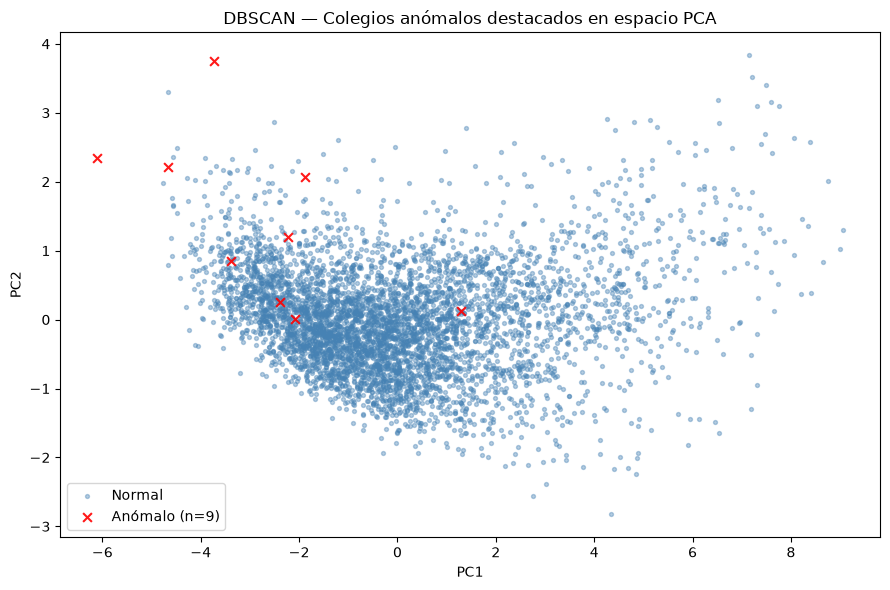

In [6]:
# Visualizar anómalos en espacio PCA
fig, ax = plt.subplots(figsize=(9,6))
mask_normal = colegios["cluster_db"] != -1
mask_anomalo = colegios["cluster_db"] == -1
ax.scatter(coords_col[mask_normal,0], coords_col[mask_normal,1],
           alpha=0.4, s=8, c="steelblue", label="Normal")
ax.scatter(coords_col[mask_anomalo,0], coords_col[mask_anomalo,1],
           alpha=0.9, s=40, c="red", marker="x", linewidths=1.5, label=f"Anómalo (n={mask_anomalo.sum()})")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("DBSCAN — Colegios anómalos destacados en espacio PCA")
ax.legend(); plt.tight_layout(); plt.show()

**Análisis Tarea 2.** DBSCAN (`eps=1.0`, `min_samples=3`) marca solo **9 colegios como ruido (0,2 %)**. En promedio puntúan más bajo que los normales (≈38–43 vs 47–53), pero el promedio esconde lo importante: la mayoría no son "extremadamente bajos" sino **combinaciones inusuales entre áreas**, casi siempre por inglés.

| Patrón | Colegios | Rasgo |
|---|---|---|
| Inglés muy por encima del resto | First Baptist School y Brooks Hill Bilingual (San Andrés), I.E. Junín (Providencia) | Inglés 56–69 con las demás áreas en 36–55: comunidades raizales con inglés como lengua materna |
| Inglés casi nulo | Internado Indígena San Antonio, Ntra. Sra. de Fátima y Urbana Mixta N°1 (Manaure, La Guajira) | Inglés 18–23 con las demás áreas en 33–50: etnoeducación wayuu, donde el español ya es segunda lengua |
| Inglés alto en contexto bajo | IE Nuestra Señora de la Candelaria (Bagadó, Chocó) | Inglés 53 con el resto en 40–44 |
| Todo muy bajo | IE Indígena de Pescadito (Bagadó, Chocó) | Entre 25 y 32 en todas las áreas |
| Estrato alto, puntaje bajo | Esther Etelvina Aramburo (Buenaventura) | Estrato 3,5 (el más alto del grupo) con puntajes entre 33 y 37 |

**¿Qué tienen en común?** 8 de 9 son oficiales (75 % en el total) y 6 de 9 son rurales (17 % en el total), y se concentran en **territorios étnicos**: San Andrés y Providencia, La Guajira, Chocó y Buenaventura. La jornada no muestra un patrón claro: 6 de 9 son de mañana, que también es la jornada más común en el total (47 %).

En el gráfico se ve que varios anómalos quedan **dentro** de la nube en 2D: son raros en el espacio completo de 6 variables (por la dimensión inglés), no en la proyección. Son colegios **distintos**, no necesariamente "malos", y no los representa bien ningún perfil general.

## Tarea 3 (15 min) — ¿Suave o duro?

Usando el mismo K que encontraste en la Tarea 1:

1. Aplica GMM con el mismo K sobre los colegios.
2. Compara las métricas (Silhouette, Davies-Bouldin) de K-Means vs GMM.
3. Identifica los colegios con **alta incertidumbre** (probabilidad máxima < 0.70). ¿Qué tipo de colegio tiende a quedar "entre dos clusters"?
4. ¿En qué caso preferirías el output probabilístico de GMM sobre el duro de K-Means para tomar decisiones de política educativa?

In [7]:
# TODO 1: GMM
gmm_col = GaussianMixture(n_components=K_col, random_state=42)
gmm_col.fit(X_colegios)
colegios["cluster_gmm"] = gmm_col.predict(X_colegios)

# TODO 2: métricas
sil_km_c  = silhouette_score(X_colegios, colegios["cluster"])
sil_gmm_c = silhouette_score(X_colegios, colegios["cluster_gmm"])
db_km_c   = davies_bouldin_score(X_colegios, colegios["cluster"])
db_gmm_c  = davies_bouldin_score(X_colegios, colegios["cluster_gmm"])
print(f"K-Means  → Silhouette: {sil_km_c:.4f}  |  Davies-Bouldin: {db_km_c:.4f}")
print(f"GMM      → Silhouette: {sil_gmm_c:.4f}  |  Davies-Bouldin: {db_gmm_c:.4f}")

print("\nCoincidencia K-Means (filas) vs GMM (columnas):")
print(pd.crosstab(colegios["cluster"], colegios["cluster_gmm"]))
print("\nPerfil por cluster GMM:")
print(colegios.groupby("cluster_gmm")[PUNTAJES + ["ESTRATO_NUM"]].mean().round(1))

# TODO 3: colegios inciertos
proba = gmm_col.predict_proba(X_colegios)
colegios["max_proba"] = proba.max(axis=1)
inciertos = colegios[colegios["max_proba"] < 0.70]
seguros = colegios[colegios["max_proba"] >= 0.70]
print(f"\nColegios inciertos (prob < 70%): {len(inciertos)} ({len(inciertos)/len(colegios)*100:.1f}%)")
print(inciertos[["COLE_NATURALEZA","COLE_AREA_UBICACION","max_proba"] + PUNTAJES].head(10))

print("\nPerfil inciertos vs seguros:")
print(pd.concat([
    inciertos[PUNTAJES + ["ESTRATO_NUM"]].mean().rename("Inciertos"),
    seguros[PUNTAJES + ["ESTRATO_NUM"]].mean().rename("Seguros")
], axis=1).round(1))
for col in ["COLE_NATURALEZA", "COLE_AREA_UBICACION"]:
    print(f"\n{col} (% dentro de cada grupo):")
    print(pd.concat([
        inciertos[col].value_counts(normalize=True).rename("Inciertos"),
        seguros[col].value_counts(normalize=True).rename("Seguros")
    ], axis=1).mul(100).round(1))

K-Means  → Silhouette: 0.4967  |  Davies-Bouldin: 0.7587
GMM      → Silhouette: 0.4528  |  Davies-Bouldin: 0.8540

Coincidencia K-Means (filas) vs GMM (columnas):
cluster_gmm     0     1
cluster                
0            3347   148
1             327  1212

Perfil por cluster GMM:
             PUNT_LECTURA_CRITICA  PUNT_MATEMATICAS  PUNT_C_NATURALES  \
cluster_gmm                                                             
0                            49.9              47.8              46.1   
1                            59.6              58.5              55.9   

             PUNT_SOCIALES_CIUDADANAS  PUNT_INGLES  ESTRATO_NUM  
cluster_gmm                                                      
0                                44.0         45.3          1.8  
1                                55.0         59.9          2.8  

Colegios inciertos (prob < 70%): 514 (10.2%)
                                                   COLE_NATURALEZA  \
COLE_NOMBRE_ESTABLECIMIENTO                

**Análisis Tarea 3.**

| Modelo | Silhouette (↑ mejor) | Davies-Bouldin (↓ mejor) |
|---|---|---|
| K-Means | **0,497** | **0,759** |
| GMM | 0,453 | 0,854 |

K-Means gana en ambas métricas. Es lo esperable: Silhouette y Davies-Bouldin premian clusters compactos y esféricos, que es justo lo que optimiza K-Means; GMM ajusta elipses con covarianza completa y esas métricas lo castigan. Los dos modelos encuentran los mismos dos niveles (bajo y alto), pero 475 colegios (9,4 %) cambian de grupo entre uno y otro. El grupo alto de GMM es más pequeño y exclusivo (1.360 colegios, estrato 2,8) que el de K-Means (1.539, estrato 2,6).

**Colegios inciertos (probabilidad máxima < 0,70): 514 (10,2 %).** Tienen puntajes **intermedios** (lectura 55 y matemáticas 53, frente a 52 y 50 de los colegios "seguros"), justo entre el promedio del grupo bajo (~47) y el del alto (~58). Son más urbanos (90 % vs 82 %), algo más oficiales (79 % vs 75 %) y del mismo estrato (2,1). El colegio que queda "entre dos clusters" es el **colegio urbano de desempeño medio-alto**: oficiales urbanos buenos y privados de bajo costo, incluidos programas de bachillerato para adultos y a distancia, que aparecen entre los ejemplos.

**¿Cuándo preferirías GMM sobre K-Means para política educativa?**

- **Focalización con presupuesto limitado:** se puede priorizar por la probabilidad de pertenecer al grupo bajo en vez de por una etiqueta binaria, y mover el umbral según el costo del error (dejar fuera de un programa de apoyo a un colegio que lo necesita cuesta más que incluir uno de más).
- **Intervención preventiva:** el 10 % de colegios frontera puede caer al grupo bajo o pasar al alto con poco esfuerzo; ahí una intervención rinde más que en los extremos.
- **Seguimiento en el tiempo:** si la probabilidad del grupo alto de un colegio sube año tras año, se ve una mejora aunque su etiqueta dura todavía no cambie.
- **No estigmatizar:** asignar "grupo bajo" a un colegio con probabilidad 0,52 comunica una certeza que no existe.

K-Means sigue siendo preferible cuando se necesita una regla simple y estable para reportar, y en este caso tiene mejores métricas internas.

## Checkpoint del profesor (10 min)

Discutimos:
- ¿Qué K elegiste y por qué (Elbow o Silhouette)?
- ¿Los colegios anómalos de DBSCAN son "malos" o simplemente "distintos"?
- ¿Tiene sentido usar PCA antes de aplicar clustering? ¿Cuándo sí y cuándo no?

**Respuestas preparadas para el checkpoint**

- **¿Qué K elegimos y por qué?** K=2 por **Silhouette**: es el máximo (0,497) y baja de forma monótona (0,411 con K=3, 0,363 con K=4). El codo sugiere **K=3**, porque la mayor caída de inercia ocurre de 2 a 3 y desde 4 la curva se aplana. Elegimos Silhouette porque es una medida objetiva de separación, sabiendo que K=2 solo distingue "alto" de "bajo"; con K=3 se ganaría un nivel intermedio a costa de una separación peor.
- **¿Los anómalos de DBSCAN son "malos" o "distintos"?** Distintos. 7 de los 9 tienen un perfil desbalanceado, con inglés muy alto (sobre todo colegios raizales de San Andrés y Providencia) o casi nulo (colegios wayuu de Manaure). Su "anomalía" refleja contextos lingüísticos y étnicos, no necesariamente un bajo desempeño general, y necesitan políticas específicas (etnoeducación, bilingüismo), no la misma intervención del cluster grande.
- **¿PCA antes de clustering?** **Sí** cuando hay muchas variables correlacionadas: aquí los 5 puntajes tienen correlaciones mayores a 0,9 y PC1 explica el 87,4 % de la varianza, así que sin PCA ese factor común "vota" cinco veces; además reduce ruido y costo de cómputo. **No** cuando hay pocas variables (aquí son 6), cuando se necesita interpretar los clusters en las variables originales, o cuando la señal está en componentes de poca varianza. El caso DBSCAN lo muestra: varios anómalos se ven normales en el plano PC1–PC2 porque su rareza está en el inglés, que el PCA de 2 componentes casi descarta.

## Tarea 4 (20 min) — ¿Colombia mejoró entre 2019 y 2022?

1. Calcula el puntaje promedio por departamento para el período **20194** y para **20224** por separado.
2. Aplica clustering jerárquico (Ward) sobre los promedios de 2019 y compara con los de 2022.
3. Grafica ambos dendrogramas lado a lado.
4. ¿Qué departamentos cambiaron de "grupo" entre 2019 y 2022?
5. ¿Es posible afirmar que Colombia "mejoró" globalmente? ¿Qué métricas usarías para responder esa pregunta?

Departamentos comunes 2019-2022: 33


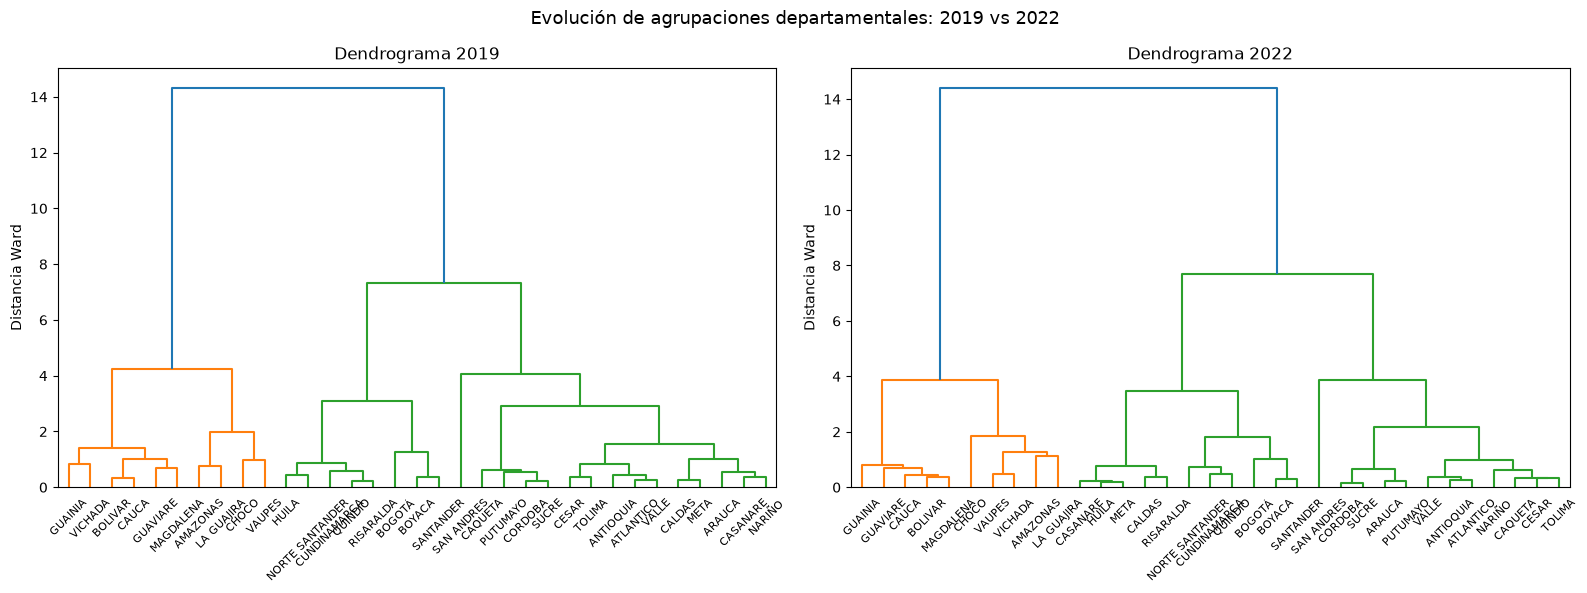


Grupo de cada departamento (según puntaje medio del grupo en su año):
          Depto Grupo_2019 Grupo_2022  Promedio_2019  Promedio_2022
          CHOCO       Bajo       Bajo          40.34          41.33
         VAUPES       Bajo       Bajo          41.53          42.60
       AMAZONAS       Bajo       Bajo          42.83          44.16
     LA GUAJIRA       Bajo       Bajo          43.00          43.66
        VICHADA       Bajo       Bajo          43.77          42.95
      MAGDALENA       Bajo       Bajo          44.15          45.41
        GUAINIA       Bajo       Bajo          44.40          45.36
       GUAVIARE       Bajo       Bajo          44.66          45.12
          CAUCA       Bajo       Bajo          45.23          45.85
        BOLIVAR       Bajo       Bajo          45.33          45.94
        CAQUETA      Medio      Medio          46.45          48.48
          SUCRE      Medio      Medio          46.63          47.22
        CORDOBA      Medio      Medio        


=== Promedio por área (todos los estudiantes de la muestra) ===
                           2019   2022  Cambio
PUNT_LECTURA_CRITICA      52.17  52.77    0.60
PUNT_MATEMATICAS          50.62  50.55   -0.08
PUNT_C_NATURALES          48.26  49.05    0.80
PUNT_SOCIALES_CIUDADANAS  46.23  47.68    1.45
PUNT_INGLES               48.46  49.82    1.36

Promedio de los 5 puntajes → 2019: 49.15 | 2022: 49.97

Departamentos que mejoraron su promedio: 31 de 33
COLE_DEPTO_UBICACION
VICHADA           -0.82
ARAUCA            -0.24
NARIÑO             0.45
GUAVIARE           0.46
PUTUMAYO           0.48
HUILA              0.59
SUCRE              0.59
CORDOBA            0.59
BOLIVAR            0.61
CAUCA              0.62
LA GUAJIRA         0.66
ATLANTICO          0.78
ANTIOQUIA          0.79
RISARALDA          0.85
SANTANDER          0.86
BOGOTÁ             0.90
CESAR              0.93
GUAINIA            0.96
TOLIMA             0.96
CHOCO              0.99
META               0.99
NORTE SANTANDER    1.

In [8]:
# TODO 1: promedios por departamento y período
prof_2019 = (df[df["PERIODO"] == 20194]
             .groupby("COLE_DEPTO_UBICACION")[PUNTAJES].mean().dropna())
prof_2022 = (df[df["PERIODO"] == 20224]
             .groupby("COLE_DEPTO_UBICACION")[PUNTAJES].mean().dropna())
# Departamentos comunes
deptos_comunes = prof_2019.index.intersection(prof_2022.index)
prof_2019 = prof_2019.loc[deptos_comunes]
prof_2022 = prof_2022.loc[deptos_comunes]
print(f"Departamentos comunes 2019-2022: {len(deptos_comunes)}")

# TODO 2-3: clustering jerárquico + dendrogramas
# Cada año se escala por separado: los grupos describen la posición RELATIVA de cada
# departamento frente a los demás en ese año (la mejora absoluta se mide en el TODO 5)
X_2019 = StandardScaler().fit_transform(prof_2019)
X_2022 = StandardScaler().fit_transform(prof_2022)

linked_2019 = linkage(X_2019, method='ward')
linked_2022 = linkage(X_2022, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, linked, etiquetas, titulo in [
    (axes[0], linked_2019, prof_2019.index.tolist(), "Dendrograma 2019"),
    (axes[1], linked_2022, prof_2022.index.tolist(), "Dendrograma 2022")
]:
    dendrogram(linked, labels=etiquetas, ax=ax, leaf_rotation=45, leaf_font_size=8)
    ax.set_title(titulo)
    ax.set_ylabel("Distancia Ward")
plt.suptitle("Evolución de agrupaciones departamentales: 2019 vs 2022", fontsize=13)
plt.tight_layout(); plt.show()

# TODO 4: departamentos que cambiaron de cluster
def ordenar_por_puntaje(etiquetas, perfiles):
    # Las etiquetas de cada ajuste son arbitrarias (el "0" de 2019 no es el "0" de 2022):
    # se renumeran por puntaje medio del grupo (0 = más bajo) para poder compararlas
    media_grupo = perfiles.mean(axis=1).groupby(etiquetas).mean().sort_values()
    mapa = {original: nuevo for nuevo, original in enumerate(media_grupo.index)}
    return np.array([mapa[e] for e in etiquetas])

etiq_2019 = ordenar_por_puntaje(AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_2019), prof_2019)
etiq_2022 = ordenar_por_puntaje(AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_2022), prof_2022)
NOMBRES_GRUPO = {0: "Bajo", 1: "Medio", 2: "Alto"}

cambios = pd.DataFrame({
    "Depto": deptos_comunes,
    "Grupo_2019": pd.Series(etiq_2019).map(NOMBRES_GRUPO),
    "Grupo_2022": pd.Series(etiq_2022).map(NOMBRES_GRUPO),
    "Promedio_2019": prof_2019.mean(axis=1).round(2).values,
    "Promedio_2022": prof_2022.mean(axis=1).round(2).values,
})
print("\nGrupo de cada departamento (según puntaje medio del grupo en su año):")
print(cambios.sort_values("Promedio_2019").to_string(index=False))
cambios_reales = cambios[cambios["Grupo_2019"] != cambios["Grupo_2022"]]
print(f"\nDepartamentos que cambiaron de grupo: {len(cambios_reales)}")
print(cambios_reales.to_string(index=False))

# TODO 5: análisis comparativo (métricas absolutas, a nivel de estudiante)
nacional = pd.DataFrame({
    "2019": df[df["PERIODO"] == 20194][PUNTAJES].mean(),
    "2022": df[df["PERIODO"] == 20224][PUNTAJES].mean(),
})
nacional["Cambio"] = nacional["2022"] - nacional["2019"]
print("\n=== Promedio por área (todos los estudiantes de la muestra) ===")
print(nacional.round(2))
print(f"\nPromedio de los 5 puntajes → 2019: {nacional['2019'].mean():.2f} | 2022: {nacional['2022'].mean():.2f}")

delta_depto = (prof_2022 - prof_2019).mean(axis=1).sort_values()
print(f"\nDepartamentos que mejoraron su promedio: {(delta_depto > 0).sum()} de {len(delta_depto)}")
print(delta_depto.round(2).to_string())

dispersion = {anio: perfil.mean(axis=1).std() for anio, perfil in [("2019", prof_2019), ("2022", prof_2022)]}
print(f"\nDesviación estándar entre departamentos → 2019: {dispersion['2019']:.2f} | 2022: {dispersion['2022']:.2f}")

**Análisis Tarea 4.** La muestra trae 33 departamentos (Bogotá cuenta aparte) y ~125.000 estudiantes por período.

**Dendrogramas.** La estructura es muy estable. El primer corte (distancia Ward ≈ 14,3 en 2019 y ≈ 14,4 en 2022) separa los mismos **10 departamentos de menor desempeño** en ambos años: Chocó, Vaupés, Amazonas, La Guajira, Vichada, Magdalena, Guainía, Guaviare, Cauca y Bolívar (Pacífico, Caribe y Amazonía-Orinoquía). Que esa distancia no se haya reducido indica que la brecha **relativa** con el resto del país no se cerró.

**¿Quién cambió de grupo?** Con las etiquetas alineadas por puntaje (sin ese paso, el "cluster 0" de 2019 y el de 2022 no significan lo mismo y aparecen cambios falsos), solo **Caldas, Casanare y Meta** cambiaron: pasaron de Medio a Alto. Mejoraron entre 1,0 y 1,4 puntos, más que el promedio nacional (+0,82). Ningún departamento bajó de grupo. Como cada año se escala por separado, "cambiar de grupo" significa mejorar **frente a los demás**, no en términos absolutos.

**¿Colombia "mejoró"?** Levemente, y con matices:

- El promedio de las 5 áreas pasó de **49,15 a 49,97 (+0,82)** y **31 de 33 departamentos** subieron; solo bajaron Vichada (−0,82) y Arauca (−0,24).
- La mejora no es pareja: sociales (+1,45) e inglés (+1,36) suben, pero **matemáticas queda plana (−0,08)**.
- La dispersión entre departamentos **aumentó** (desviación estándar 3,17 → 3,32): mejoró el promedio, pero no la equidad territorial.
- El efecto es pequeño: 0,82 puntos frente a una desviación estándar de ~10,4 en el puntaje promedio por estudiante (d de Cohen ≈ 0,08).

No se puede afirmar con estos datos que el sistema educativo "mejoró": son cohortes distintas, 2022 es posterior a la pandemia, es una muestra y se asume que la escala del ICFES es comparable entre años.

**Métricas que usaríamos:** la diferencia de medias por área con intervalo de confianza y **tamaño del efecto** (con n ≈ 125.000 casi cualquier diferencia sale "significativa"); **percentiles** (P10, P50, P90) para ver si mejoran los de abajo o los de arriba; el porcentaje de estudiantes por **nivel de desempeño** del ICFES; las **brechas** entre departamentos, oficial-privado y urbano-rural; y una comparación por **colegio** (panel 2019 vs 2022) para controlar cambios en la composición de la muestra.

## Tarea 5 (10 min) — Clustering en el P2/3

1. Sobre el dataset del proyecto de tu grupo, aplica K-Means (o DBSCAN si tiene sentido) como el **modelo no supervisado requerido** en la Fase C.
2. Calcula el Silhouette Score.
3. Describe en 3-4 frases qué significan los clusters encontrados en términos del negocio/dominio de tu dataset.

Casos cargados: 480,091 de 1,500 municipios
Municipios con ≥30 casos: 606


 K   Inercia  Silhouette
 2 3805.6682      0.2645
 3 3030.3990      0.2280
 4 2493.2684      0.2514
 5 2202.9053      0.2526
 6 2029.6860      0.2411
 7 1899.8860      0.2031
 8 1781.6232      0.2030


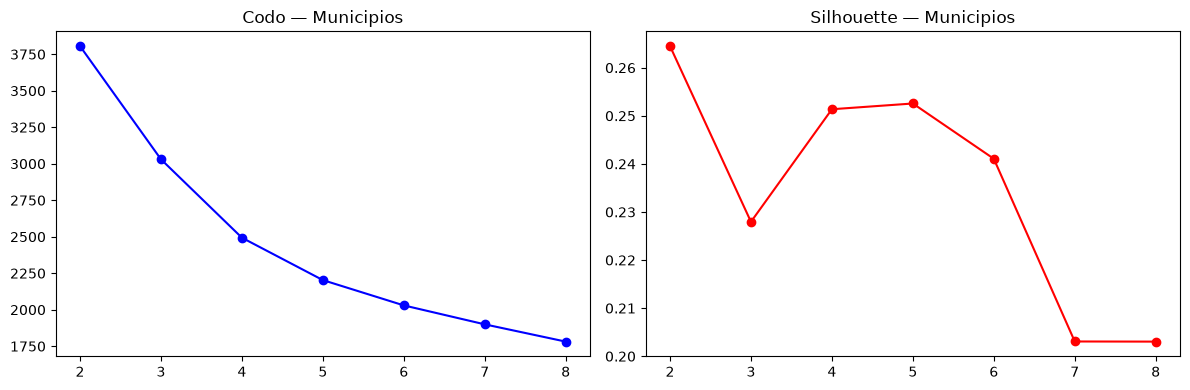


Silhouette Score del proyecto (K=4): 0.2514

=== Perfil por cluster (promedios) ===
         TOTAL_CASOS  P_HURTO_PERSONAS  P_VIOLENCIA_INTRAFAM  P_HURTO_RESIDENCIAS  P_HOMICIDIO  P_TRANSITO  P_VICTIMA_FEMENINA  P_ARMA_FUEGO  n_municipios
cluster                                                                                                                                                   
0           3223.128             0.537                 0.306                0.081        0.045       0.027               0.497         0.145           133
1             89.924             0.225                 0.285                0.053        0.339       0.053               0.351         0.430            66
2            100.776             0.240                 0.561                0.094        0.061       0.040               0.584         0.087           210
3             83.330             0.331                 0.328                0.153        0.080       0.099               0.441         0.144

In [9]:
from pathlib import Path

# Dataset del proyecto (Grupo 7): estadísticas delictivas 2025 de la Policía Nacional (DIJIN).
# Son 8 reportes .xlsx (uno por delito) con 10 filas de membrete y pie de página; se cargan
# igual que en la Fase B (entrega/fase_b_etl.ipynb del repositorio del grupo).
CARPETA_PROYECTO = Path("..", "Grupo-7-p-1", "Grupo-7-p1", "datos")
marcos = []
for archivo in sorted(CARPETA_PROYECTO.glob("*.xlsx")):
    datos = pd.read_excel(archivo, header=10)
    datos.columns = [c.strip() for c in datos.columns]
    datos["TIPO_DELITO"] = archivo.stem.removesuffix("2025").strip().upper()
    marcos.append(datos)
df_proyecto = pd.concat(marcos, ignore_index=True).dropna(subset=["CODIGO DANE"])
df_proyecto["CODIGO DANE"] = df_proyecto["CODIGO DANE"].astype("int64").astype(str)
print(f"Casos cargados: {len(df_proyecto):,} de {df_proyecto['CODIGO DANE'].nunique():,} municipios")

# Unidad de análisis: el municipio. Se describe con su volumen de casos y su MEZCLA delictiva
# (proporciones), para agrupar municipios por el tipo de criminalidad y no solo por su tamaño.
por_tipo = pd.crosstab(df_proyecto["CODIGO DANE"], df_proyecto["TIPO_DELITO"])
total = por_tipo.sum(axis=1)
municipios = pd.DataFrame({"TOTAL_CASOS": total, "LOG_TOTAL": np.log1p(total)})
for delito, columna in [("HURTO A PERSONAS", "P_HURTO_PERSONAS"),
                        ("VIOLENCIA INTRAFAMILIAR", "P_VIOLENCIA_INTRAFAM"),
                        ("HURTO A RESIDENCIAS", "P_HURTO_RESIDENCIAS"),
                        ("HOMICIDIO INTENCIONAL", "P_HOMICIDIO"),
                        ("HOMICIDIOS EN ACCIDENTE DE TRÁNSITO", "P_TRANSITO")]:
    municipios[columna] = por_tipo[delito] / total
grupos = df_proyecto.groupby("CODIGO DANE")
municipios["P_VICTIMA_FEMENINA"] = grupos["GENERO"].apply(lambda s: (s == "FEMENINO").mean())
municipios["P_ARMA_FUEGO"] = grupos["ARMAS MEDIOS"].apply(lambda s: (s == "ARMA DE FUEGO").mean())
municipios[["DEPARTAMENTO", "MUNICIPIO"]] = grupos[["DEPARTAMENTO", "MUNICIPIO"]].first()
# Con pocos casos las proporciones son ruido (1 homicidio de 2 casos = 50 %): mínimo 30 casos
municipios = municipios[municipios["TOTAL_CASOS"] >= 30]
print(f"Municipios con ≥30 casos: {len(municipios):,}")

features = ["LOG_TOTAL", "P_HURTO_PERSONAS", "P_VIOLENCIA_INTRAFAM", "P_HURTO_RESIDENCIAS",
            "P_HOMICIDIO", "P_TRANSITO", "P_VICTIMA_FEMENINA", "P_ARMA_FUEGO"]
X_proy = StandardScaler().fit_transform(municipios[features])

# Elección de K: codo + Silhouette
inercias_p, silhouettes_p = [], []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_proy)
    inercias_p.append(km.inertia_)
    silhouettes_p.append(silhouette_score(X_proy, km.labels_))
print(pd.DataFrame({"K": range(2, 9), "Inercia": inercias_p, "Silhouette": silhouettes_p}).round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(2, 9), inercias_p, "b-o"); axes[0].set_title("Codo — Municipios")
axes[1].plot(range(2, 9), silhouettes_p, "r-o"); axes[1].set_title("Silhouette — Municipios")
plt.tight_layout(); plt.show()

# K=4: Silhouette casi igual al máximo (K=2) pero separa perfiles delictivos útiles para el negocio
K_PROY = 4
km_proy = KMeans(n_clusters=K_PROY, n_init=10, random_state=42)
municipios["cluster"] = km_proy.fit_predict(X_proy)
sil_proy = silhouette_score(X_proy, municipios["cluster"])
print(f"\nSilhouette Score del proyecto (K={K_PROY}): {sil_proy:.4f}")

print("\n=== Perfil por cluster (promedios) ===")
perfil_proy = municipios.groupby("cluster")[["TOTAL_CASOS"] + features[1:]].mean()
perfil_proy["n_municipios"] = municipios["cluster"].value_counts()
print(perfil_proy.round(3).to_string())

print("\n=== Municipios con más casos en cada cluster ===")
for k in range(K_PROY):
    ejemplos = municipios[municipios["cluster"] == k].nlargest(6, "TOTAL_CASOS")["MUNICIPIO"].tolist()
    print(f"Cluster {k}: {', '.join(ejemplos)}")

**Interpretación de negocio de los clusters**

Dataset del proyecto: estadísticas delictivas 2025 de la Policía Nacional (DIJIN), 480.091 casos de 8 delitos. Se agruparon los **606 municipios con ≥ 30 casos** según su volumen y su **mezcla delictiva**. **Silhouette = 0,251** con K=4, una estructura débil-moderada: los perfiles se solapan. K=2 tenía una Silhouette apenas mayor (0,265), pero solo separa ciudades grandes de municipios pequeños; K=4 conserva casi la misma calidad, coincide con el codo y separa **tipos de criminalidad**, que es lo útil para el proyecto.

| Cluster | Nombre | Municipios | Rasgos | Ejemplos |
|---|---|---|---|---|
| 0 | Ciudades de hurto callejero | 133 | ~3.200 casos en promedio; 54 % hurto a personas | Bogotá, Medellín, Cali, Barranquilla, Cartagena, Soacha |
| 1 | Violencia letal armada | 66 | 34 % homicidios intencionales; 43 % con arma de fuego; 65 % víctimas hombres | Puerto Tejada, Zona Bananera, Tibú, Fundación, El Tambo, Patía |
| 2 | Violencia intrafamiliar | 210 | 56 % violencia intrafamiliar; 58 % víctimas mujeres; solo 9 % con arma de fuego | Apartadó, Caucasia, Tumaco, San José del Guaviare, Magangué |
| 3 | Delito patrimonial y vial | 197 | Mayor proporción de hurto a residencias (15 %) y de muertes en accidentes de tránsito (10 %) | Rivera, Agustín Codazzi, Piendamó, Tame, La Tebaida, Aguazul |

La criminalidad municipal en Colombia no es un solo fenómeno. Las grandes ciudades concentran el delito patrimonial en la vía pública. Un grupo pequeño de municipios, varios en zonas con presencia de conflicto armado como el Catatumbo y el Cauca, concentra la violencia homicida con armas de fuego. La mayoría de municipios intermedios reporta sobre todo violencia intrafamiliar contra mujeres. Para el proyecto esto sugiere **estrategias diferenciadas** por cluster: prevención del hurto en el 0, control de armas y presencia institucional en el 1, rutas de atención de violencia de género en el 2 y seguridad vial y rural en el 3.

*Limitación:* las variables son proporciones dentro de los 8 delitos del dataset, no tasas por habitante (el dataset no trae población), y en los municipios pequeños la mezcla puede reflejar subregistro.

## Entrega

**Nombre del archivo:** `02_laboratorio_apellido1_apellido2.ipynb`

**Sube a:** Moodle → Clase 7 → Laboratorio.

**Criterios de evaluación:**
- Tareas 1-4: código funcional + análisis escrito de los resultados
- Tarea 5: aplicado al dataset del proyecto con interpretación de negocio
- Reflexiones escritas en celdas markdown